# Brain-Diffuser — Stage 1 (VDVAE)

Sets up [ozcelikfu/brain-diffuser](https://github.com/ozcelikfu/brain-diffuser) and runs the
**low-level (VDVAE) reconstruction** for one subject, from scratch.


## 1. Check the GPU and RAM

In [1]:
import torch, psutil
print("torch:", torch.__version__)
if torch.cuda.is_available():
    p = torch.cuda.get_device_properties(0)
    print(f"GPU: {p.name} ({p.total_memory/1e9:.0f} GB)")
else:
    print("No GPU. Runtime > Change runtime type > GPU.")
ram = psutil.virtual_memory().total / 1e9
print(f"System RAM: {ram:.0f} GB")
print("High-RAM (~50 GB) confirmed." if ram > 40 else
      "This looks like a standard (~13 GB) runtime - switch to High-RAM in Runtime settings.")

torch: 2.14.1+cu130
GPU: Tesla T4 (16 GB)
System RAM: 55 GB
High-RAM (~50 GB) confirmed.


## 2. Mount Google Drive

`DRIVE_DIR` is the persistent store for the expensive-to-recreate outputs.

In [2]:
import os
from google.colab import drive
drive.mount("/content/drive")

DRIVE_DIR = "/content/drive/MyDrive/brain-diffuser-data"   # persists across sessions
print("Drive persistent store:", DRIVE_DIR)

Mounted at /content/drive
Drive persistent store: /content/drive/MyDrive/brain-diffuser-data


## 0 → clean slate (run once)

Deletes everything from previous attempts — the ephemeral repo/raw data **and** the Drive store
(old `processed_data`, features, checkpoints, results). After your first clean run, set
`RESET = False`, otherwise a later kernel restart that re-runs this cell would wipe your progress
and force the 80 GB download again.

In [ ]:
RESET = False

import shutil
if RESET:
    for p in ["/content/brain-diffuser", DRIVE_DIR]:
        if os.path.isdir(p):
            shutil.rmtree(p); print("deleted", p)
    print("Clean slate ready. NOW set RESET=False above so re-runs don't wipe progress.")
else:
    print("RESET=False -> keeping existing data.")

deleted /content/drive/MyDrive/brain-diffuser-data
Clean slate ready. NOW set RESET=False above so re-runs don't wipe progress.


## 3. Clone the repo (pinned commit) and link persistent folders

Clone to `/content` (fast, ephemeral); symlink the four persistent folders into Drive. Also
patches the repo's `-sub` int bug across every script.

In [4]:
REPO = "/content/brain-diffuser"
COMMIT = "671f1403fe2a0515771c29d64fb839153cf12f5e"

if not os.path.isdir(REPO):
    !git clone https://github.com/ozcelikfu/brain-diffuser.git {REPO}
    !cd {REPO} && git checkout {COMMIT}

# Redirect persistent folders to Drive via symlinks (recreates them after a reset).
links = {
    f"{REPO}/vdvae/model":            f"{DRIVE_DIR}/model",
    f"{REPO}/data/processed_data":    f"{DRIVE_DIR}/processed_data",
    f"{REPO}/data/extracted_features":f"{DRIVE_DIR}/extracted_features",
    f"{REPO}/results":                f"{DRIVE_DIR}/results",
}
for link, target in links.items():
    os.makedirs(target, exist_ok=True)
    if os.path.islink(link):
        continue
    if os.path.isdir(link):
        shutil.rmtree(link)
    os.makedirs(os.path.dirname(link), exist_ok=True)
    os.symlink(target, link)
    print("linked", link, "->", target)

# Repo scripts read -sub as a string but format paths with {:02d}; cast to int everywhere.
import glob as _glob
for _pp in _glob.glob(f"{REPO}/scripts/*.py") + [f"{REPO}/data/prepare_nsddata.py"]:
    if not os.path.exists(_pp):
        continue
    _s = open(_pp).read()
    if "sub=args.sub" in _s:
        open(_pp, "w").write(_s.replace("sub=args.sub", "sub=int(args.sub)"))
        print("patched int(sub):", os.path.basename(_pp))

%cd {REPO}
!ls

Cloning into '/content/brain-diffuser'...
remote: Enumerating objects: 428, done.
remote: Counting objects: 100% (428/428), done.
remote: Compressing objects: 100% (279/279), done.
remote: Total 428 (delta 157), reused 390 (delta 132), pack-reused 0 (from 0)
Receiving objects: 100% (428/428), 6.15 MiB | 26.45 MiB/s, done.
Resolving deltas: 100% (157/157), done.
Note: switching to '671f1403fe2a0515771c29d64fb839153cf12f5e'.

You are in 'detached HEAD' state. You can look around, make experimental
changes and commit them, and you can discard any commits you make in this
state without impacting any branches by switching back to a branch.

If you want to create a new branch to retain commits you create, you may
do so (now or later) by using -c with the switch command. Example:

  git switch -c <new-branch-name>

Or undo this operation with:

  git switch -

Turn off this advice by setting config variable advice.detachedHead to false

HEAD is now at 671f140 Versatile Diffusion modules are a

## 4. Install dependencies

Pip onto Colab's existing PyTorch (not the repo's old `environment.yml`). Adds the VDVAE
imports, AWS CLI v2 (self-contained, avoids the pip-awscli/botocore clash), and `mpi4py`.

In [5]:
!apt-get -qq install -y libopenmpi-dev >/dev/null 2>&1
!pip install -q h5py scipy nibabel Pillow scikit-learn pandas matplotlib mpi4py psutil

# AWS CLI v2 as a self-contained binary (the pip 'awscli' crashes on import on Python 3.13).
!pip uninstall -y awscli -q 2>/dev/null
!curl -s "https://awscli.amazonaws.com/awscli-exe-linux-x86_64.zip" -o /tmp/awscliv2.zip
!cd /tmp && unzip -oq awscliv2.zip && ./aws/install --update >/dev/null 2>&1
!aws --version
print("Dependencies installed.")

aws-cli/2.41.0 Python/3.14.8 Linux/6.6.159+ exe/x86_64.ubuntu.24
Dependencies installed.


## 5. Configuration

In [6]:
SUB = 1          # subject: the paper uses 1, 2, 5, 7. Start with 1.

PROCESSED = f"{REPO}/data/processed_data/subj{SUB:02d}"
train_fmri_npy = f"{PROCESSED}/nsd_train_fmriavg_nsdgeneral_sub{SUB}.npy"
print("Target processed file:", train_fmri_npy)
print("Already prepared?", os.path.exists(train_fmri_npy))

Target processed file: /content/brain-diffuser/data/processed_data/subj01/nsd_train_fmriavg_nsdgeneral_sub1.npy
Already prepared? False


## 6. The COCO annotations file

`prepare_nsddata.py` reads `data/annots/COCO_73k_annots_curated.npy`.

In [7]:
ANNOTS_URL = "https://huggingface.co/datasets/pscotti/naturalscenesdataset/blob/ac7c3f8955dbd8b1a4de86b8b204c4cdd167ef53/COCO_73k_annots_curated.npy"   # <- paste the Hugging Face URL for COCO_73k_annots_curated.npy

annots_dir = f"{REPO}/data/annots"
annots_path = f"{annots_dir}/COCO_73k_annots_curated.npy"
os.makedirs(annots_dir, exist_ok=True)

if os.path.exists(annots_path):
    print("annots already present:", annots_path)
elif ANNOTS_URL:
    !wget -q -O {annots_path} "{ANNOTS_URL}"
    print("downloaded ->", annots_path, "| size:", os.path.getsize(annots_path), "bytes")
else:
    print("ACTION NEEDED: paste the Hugging Face URL into ANNOTS_URL and re-run,")
    print("or upload the file manually to:", annots_path)

downloaded -> /content/brain-diffuser/data/annots/COCO_73k_annots_curated.npy | size: 84041 bytes


## 7. Download NSD data

Pulls from the public bucket `s3://natural-scenes-dataset` with anonymous access for **subject
`SUB` only** (ROI + betas via `--recursive`). Writes to `data/nsddata*` on ephemeral disk.
**Skipped if `processed_data` already exists.**

In [8]:
if os.path.exists(train_fmri_npy):
    print("processed_data already exists -> SKIP download.")
else:
    print("Downloading NSD for subject", SUB, "only - ~80 GB and slow.")
    s3, A, d = "s3://natural-scenes-dataset", "aws s3 cp --no-sign-request", f"{REPO}/data"
    subj = f"subj{SUB:02d}"
    !{A} {s3}/nsddata/experiments/nsd/nsd_expdesign.mat {d}/nsddata/experiments/nsd/nsd_expdesign.mat
    !{A} {s3}/nsddata/experiments/nsd/nsd_stim_info_merged.pkl {d}/nsddata/experiments/nsd/nsd_stim_info_merged.pkl
    !{A} {s3}/nsddata_stimuli/stimuli/nsd/nsd_stimuli.hdf5 {d}/nsddata_stimuli/stimuli/nsd/nsd_stimuli.hdf5
    !{A} --recursive {s3}/nsddata/ppdata/{subj}/func1pt8mm/roi/ {d}/nsddata/ppdata/{subj}/func1pt8mm/roi/
    !{A} --recursive {s3}/nsddata_betas/ppdata/{subj}/func1pt8mm/betas_fithrf_GLMdenoise_RR/ {d}/nsddata_betas/ppdata/{subj}/func1pt8mm/betas_fithrf_GLMdenoise_RR/
    !echo "--- disk after download ---" && df -h /content | tail -1

download: s3://natural-scenes-dataset/nsddata/experiments/nsd/nsd_expdesign.mat to data/nsddata/experiments/nsd/nsd_expdesign.mat
download: s3://natural-scenes-dataset/nsddata/experiments/nsd/nsd_stim_info_merged.pkl to data/nsddata/experiments/nsd/nsd_stim_info_merged.pkl
download: s3://natural-scenes-dataset/nsddata_stimuli/stimuli/nsd/nsd_stimuli.hdf5 to data/nsddata_stimuli/stimuli/nsd/nsd_stimuli.hdf5
download: s3://natural-scenes-dataset/nsddata/ppdata/subj01/func1pt8mm/roi/floc-faces.nii.gz to data/nsddata/ppdata/subj01/func1pt8mm/roi/floc-faces.nii.gz
download: s3://natural-scenes-dataset/nsddata/ppdata/subj01/func1pt8mm/roi/lh.Kastner2015.nii.gz to data/nsddata/ppdata/subj01/func1pt8mm/roi/lh.Kastner2015.nii.gz
download: s3://natural-scenes-dataset/nsddata/ppdata/subj01/func1pt8mm/roi/MTL.nii.gz to data/nsddata/ppdata/subj01/func1pt8mm/roi/MTL.nii.gz
download: s3://natural-scenes-dataset/nsddata/ppdata/subj01/func1pt8mm/roi/floc-words.nii.gz to data/nsddata/ppdata/subj01/func1

## 8. Preprocess fMRI -> averaged arrays

Averages repeated trials and extracts the `nsdgeneral` ROI, writing the small `.npy` files Stage
1 consumes (to Drive via the symlink). Keeps the two lossless memory fixes (lazy HDF5 read,
uint8 images) — still worth it even at 50 GB.

In [9]:
# np.save won't create parent folders and the script doesn't either -> make them first.
os.makedirs(PROCESSED, exist_ok=True)
os.makedirs(f"{REPO}/data/extracted_features/subj{SUB:02d}", exist_ok=True)

if os.path.exists(train_fmri_npy):
    print("Already prepared -> SKIP.")
else:
    _pp = f"{REPO}/data/prepare_nsddata.py"
    _src = _orig = open(_pp).read()
    # (1) -sub as string -> int (covers `assert sub in [1,2,5,7]` and {:02d}).
    if "sub = int(sub);" not in _src:
        _src = _src.replace("assert sub in [1,2,5,7]", "sub = int(sub); assert sub in [1,2,5,7]")
    # (2) read the 40 GB stimuli HDF5 lazily instead of loading all 73k images at once.
    _src = _src.replace("stim = f_stim['imgBrick'][:]", "stim = f_stim['imgBrick']")
    # (3) stim_array as uint8 (images are 0-255) instead of the float64 default (8x the RAM/disk).
    _src = _src.replace("np.zeros((num_train,im_dim,im_dim,im_c))",
                        "np.zeros((num_train,im_dim,im_dim,im_c),dtype=np.uint8)")
    _src = _src.replace("np.zeros((num_test,im_dim,im_dim,im_c))",
                        "np.zeros((num_test,im_dim,im_dim,im_c),dtype=np.uint8)")
    if _src != _orig:
        open(_pp, "w").write(_src)
        print("patched prepare_nsddata.py (int cast + lazy stimuli read + uint8 images)")
    !cd {REPO}/data && python prepare_nsddata.py -sub {SUB}

# --- verification checkpoint ---
import numpy as np
assert os.path.exists(train_fmri_npy), "prepare_nsddata did not produce the training fMRI file."
fmri = np.load(train_fmri_npy)
stim = np.load(f"{PROCESSED}/nsd_train_stim_sub{SUB}.npy")
print("train fMRI:", fmri.shape, fmri.dtype, "| train stimuli:", stim.shape, stim.dtype)
print("Expect ~ (8859, ~15000) fMRI voxels and ~8859 stimulus images.")

Streaming output truncated to the last 5000 lines.
4853
4854
4855
4856
4857
4858
4859
4860
4861
4862
4863
4864
4865
4866
4867
4868
4869
4870
4871
4872
4873
4874
4875
4876
4877
4878
4879
4880
4881
4882
4883
4884
4885
4886
4887
4888
4889
4890
4891
4892
4893
4894
4895
4896
4897
4898
4899
4900
4901
4902
4903
4904
4905
4906
4907
4908
4909
4910
4911
4912
4913
4914
4915
4916
4917
4918
4919
4920
4921
4922
4923
4924
4925
4926
4927
4928
4929
4930
4931
4932
4933
4934
4935
4936
4937
4938
4939
4940
4941
4942
4943
4944
4945
4946
4947
4948
4949
4950
4951
4952
4953
4954
4955
4956
4957
4958
4959
4960
4961
4962
4963
4964
4965
4966
4967
4968
4969
4970
4971
4972
4973
4974
4975
4976
4977
4978
4979
4980
4981
4982
4983
4984
4985
4986
4987
4988
4989
4990
4991
4992
4993
4994
4995
4996
4997
4998
4999
5000
5001
5002
5003
5004
5005
5006
5007
5008
5009
5010
5011
5012
5013
5014
5015
5016
5017
5018
5019
5020
5021
5022
5023
5024
5025
5026
5027
5028
5029
5030
5031
5032
5033
5034
5035
5036
5037
5038
5039
5040
5041
5042

## 9. Free the raw data (optional, recommended)

Stage 1 no longer needs the raw betas or the 40 GB stimuli HDF5 once `processed_data` exists.
Delete them to reclaim disk (they re-download in §7 if you ever need them again).

In [ ]:
for p in [f"{REPO}/data/nsddata_betas",
          f"{REPO}/data/nsddata_stimuli/stimuli/nsd/nsd_stimuli.hdf5"]:
    if os.path.exists(p):
        (shutil.rmtree if os.path.isdir(p) else os.remove)(p); print("freed", p)
!df -h /content | tail -1

## 10. VDVAE checkpoints

Four OpenAI Very Deep VAE files into `vdvae/model/` (-> Drive, persists). ~1-2 GB.

In [10]:
model_dir = f"{REPO}/vdvae/model"
os.makedirs(model_dir, exist_ok=True)
base = "https://openaipublic.blob.core.windows.net/very-deep-vaes-assets/vdvae-assets-2"
files = ["imagenet64-iter-1600000-log.jsonl",
         "imagenet64-iter-1600000-model.th",
         "imagenet64-iter-1600000-model-ema.th",
         "imagenet64-iter-1600000-opt.th"]
for fn in files:
    dst = f"{model_dir}/{fn}"
    if os.path.exists(dst) and os.path.getsize(dst) > 0:
        print("have", fn)
    else:
        !wget -q -O {dst} {base}/{fn} && echo "downloaded {fn}"
!ls -lh {model_dir}

downloaded imagenet64-iter-1600000-log.jsonl
downloaded imagenet64-iter-1600000-model.th
downloaded imagenet64-iter-1600000-model-ema.th
downloaded imagenet64-iter-1600000-opt.th
lrwxrwxrwx 1 root root 48 Nov 18 08:54 /content/brain-diffuser/vdvae/model -> /content/drive/MyDrive/brain-diffuser-data/model


## 11. Stage 1 — VDVAE: extract -> regress -> reconstruct

Three scripts in order. With high-RAM we keep latents at full float32 (no float16 downcast).

In [11]:
!cd {REPO} && python scripts/vdvae_extract_features.py -sub {SUB}

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
Libs imported
Models is Loading
Restoring ema vae from vdvae/model/imagenet64-iter-1600000-model-ema.th
0
30
60
90
120
150
180
210
240
270
300
330
360
390
420
450
480
510
540
570
600
630
660
690
720
750
780
810
840
870
900
930
960
0
30
60
90
120
150
180
210
240
270
300
330
360
390
420
450
480
510
540
570
600
630
660
690
720
750
780
810
840
870
900
930
960
990
1020
1050
1080
1110
1140
1170
1200
1230
1260
1290
1320
1350
1380
1410
1440
1470
1500
1530
1560
1590
1620
1650
1680
1710
1740
1770
1800
1830
1860
1890
1920
1950
1980
2010
2040
2070
2100
2130
2160
2190
2220
2250
2280
2310
2340
2370
2400
2430
2460
2490
2520
2550
2580
2610
2640
2670
2700
2730
2760
2790
2820
2850
2880
2910
2940
2970
3000
3030
3060
3090
3120
3150
3180
3210
3240
3270
3300
3330
3360
3390
3420
3450
3480
3510
3540
3570
3600
3630
3660
3690
372

In [13]:
import os
# Regression loads fMRI from 'processed_data/...' but your files are under 'data/processed_data/...'
rp = f"{REPO}/scripts/vdvae_regression.py"
s = open(rp).read()
s = s.replace("'processed_data/subj{:02d}/nsd_train_fmriavg", "'data/processed_data/subj{:02d}/nsd_train_fmriavg")
s = s.replace("'processed_data/subj{:02d}/nsd_test_fmriavg",  "'data/processed_data/subj{:02d}/nsd_test_fmriavg")
open(rp, "w").write(s)
print("patched regression fMRI paths -> data/processed_data/")

# Output dirs the scripts don't create themselves:
os.makedirs(f"{REPO}/data/predicted_features/subj{SUB:02d}", exist_ok=True)  # regression writes here
os.makedirs(f"{REPO}/results/vdvae/subj{SUB:02d}", exist_ok=True)            # reconstruct writes here

!cd {REPO} && python scripts/vdvae_regression.py -sub {SUB}

patched regression fMRI paths -> data/processed_data/
-4.345760117042555e-16 0.9999435586284298
-0.027261797786477315 0.9914779354685913
24.4805317560972 -14.412738287655525
9.81827287708914 -9.315348672150476
Training latents Feature Regression
-0.024832511068562657


In [15]:
pp = f"{REPO}/scripts/vdvae_reconstruct_images.py"
s = open(pp).read()
s = s.replace("'results/vdvae/subj{:02d}/{}.png'.format(i*batch_size+j)",
              "'results/vdvae/subj{:02d}/{}.png'.format(sub,i*batch_size+j)")
open(pp, "w").write(s)
print("patched reconstruct save path -> .format(sub, idx)")

!cd {REPO} && python scripts/vdvae_reconstruct_images.py -sub {SUB}

patched reconstruct save path -> .format(sub, idx)
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
Libs imported
Models is Loading
Restoring ema vae from vdvae/model/imagenet64-iter-1600000-model-ema.th
0
30
60
90
120
150
180
210
240
270
300
330
360
390
420
450
480
510
540
570
600
630
660
690
720
750
780
810
840
870
900
930
960
0
30
60
90
120
150
180
210
240
270
300
330
360
390
420
450
480
510
540
570
600
630
660
690
720
750
780
810
840
870
900
930
960


## 12. Look at the reconstructions

Low-level VDVAE outputs: blurry, but layout/color should match the viewed images. Stage-1 done.

found 982 result images under results/


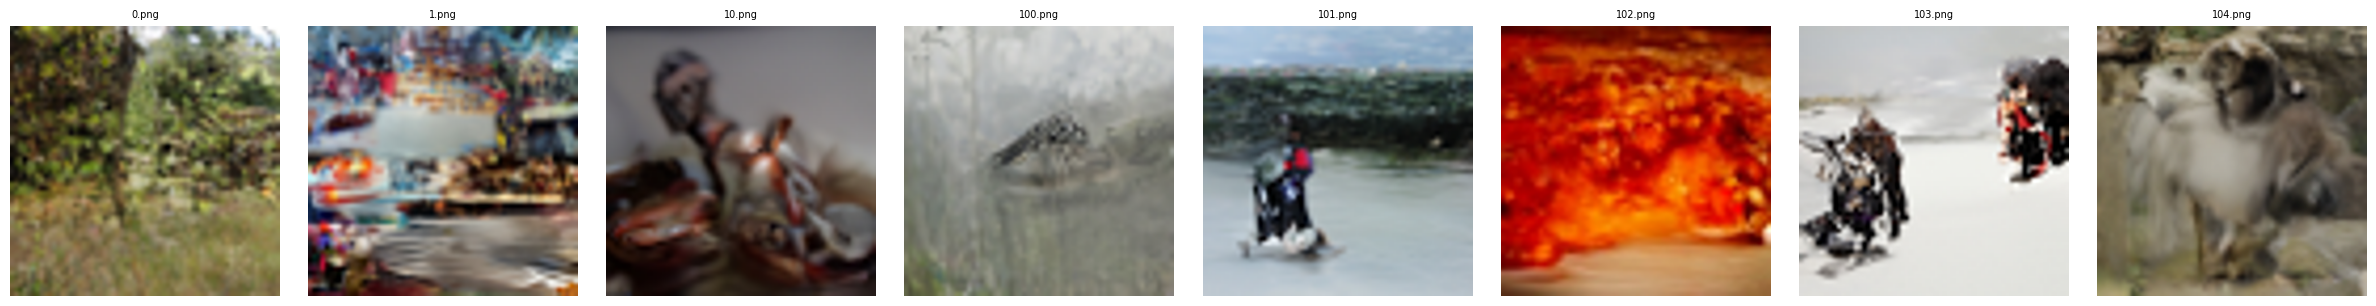

In [16]:
import glob
from PIL import Image
import matplotlib.pyplot as plt

cands = sorted(glob.glob(f"{REPO}/results/**/*.png", recursive=True) +
               glob.glob(f"{REPO}/results/**/*.jpg", recursive=True))
print(f"found {len(cands)} result images under results/")
if not cands:
    print("None yet. Check the reconstruct cell's output for the exact path it wrote to.")
else:
    show = cands[:8]
    fig, axes = plt.subplots(1, len(show), figsize=(3 * len(show), 3))
    for ax, p in zip(np.atleast_1d(axes), show):
        ax.imshow(Image.open(p)); ax.axis("off"); ax.set_title(os.path.basename(p), fontsize=7)
    plt.tight_layout(); plt.show()

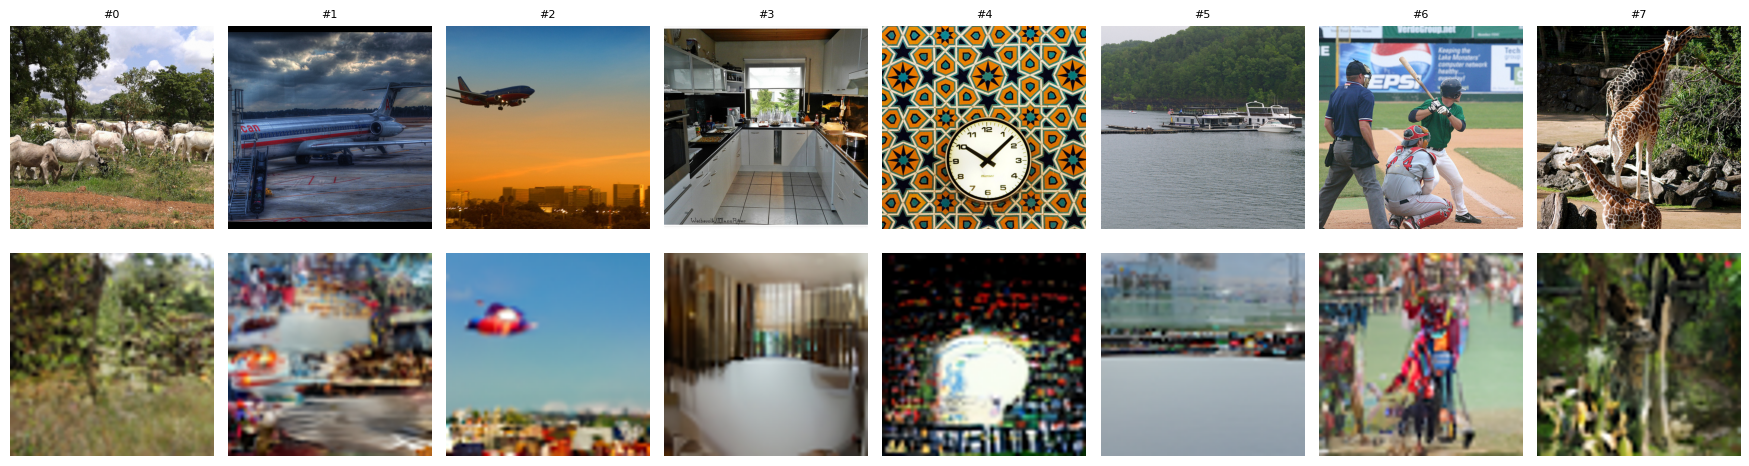

In [17]:
import os, glob, numpy as np
from PIL import Image
import matplotlib.pyplot as plt

recon_dir = f"{REPO}/results/vdvae/subj{SUB:02d}"
test_stim = np.load(f"{REPO}/data/processed_data/subj{SUB:02d}/nsd_test_stim_sub{SUB}.npy")  # (982,425,425,3) uint8
cap_path  = f"{REPO}/data/processed_data/subj{SUB:02d}/nsd_test_cap_sub{SUB}.npy"
caps = np.load(cap_path, allow_pickle=True) if os.path.exists(cap_path) else None

idxs = [0, 1, 2, 3, 4, 5, 6, 7]           # which test images to show
fig, axes = plt.subplots(2, len(idxs), figsize=(2.2*len(idxs), 5))
for c, j in enumerate(idxs):
    axes[0, c].imshow(test_stim[j]);                 axes[0, c].axis("off")
    axes[1, c].imshow(Image.open(f"{recon_dir}/{j}.png")); axes[1, c].axis("off")
    axes[0, c].set_title(f"#{j}", fontsize=8)
axes[0, 0].set_ylabel("SEEN", fontsize=11)
axes[1, 0].set_ylabel("RECON", fontsize=11)
plt.tight_layout(); plt.show()

if caps is not None:
    for j in idxs:
        print(f"#{j} caption:", caps[j])